In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# 1. Load Data
file_path = '/content/drive/MyDrive/cicids2017_cleaned.csv'
df = pd.read_csv(file_path)

# 2. Create Binary_Label
df['Binary_Label'] = df['Attack Type'].apply(lambda x: 0 if x == 'Normal Traffic' else 1)

# 3. Clean Data
df.replace([np.inf, -np.inf], np.nan, inplace=True)
df.dropna(inplace=True)

# 4. MIN-MAX SCALING
# We only scale the numerical features (X), not the labels (y)
scaler = MinMaxScaler()

# Identify features to scale (everything except the target labels)
features = df.drop(['Attack Type', 'Binary_Label'], axis=1)

# Apply scaling
scaled_features = scaler.fit_transform(features)

# Convert back to a DataFrame
df_scaled = pd.DataFrame(scaled_features, columns=features.columns)

print("Success! Data Cleaned and Min-Max Scaled to range [0, 1].")
print(df_scaled.head())

Success! Data Cleaned and Min-Max Scaled to range [0, 1].
   Destination Port  Flow Duration  Total Fwd Packets  \
0          0.000336   1.055296e-02           0.000182   
1          0.000336   1.099472e-02           0.000182   
2          0.000336   1.441667e-06           0.000000   
3          0.000336   1.086251e-02           0.000182   
4          0.540108   7.499999e-07           0.000000   

   Total Length of Fwd Packets  Fwd Packet Length Max  Fwd Packet Length Min  \
0                     0.000207               0.018372                    0.0   
1                     0.000207               0.018372                    0.0   
2                     0.000000               0.000000                    0.0   
3                     0.000211               0.018372                    0.0   
4                     0.000000               0.000000                    0.0   

   Fwd Packet Length Mean  Fwd Packet Length Std  Bwd Packet Length Max  \
0                0.010937               0.0

In [ ]:
import numpy as np

# --- STEP 1: DROP IDENTIFIERS ("Cheating" Columns) ---
# We remove columns that make the model memorize instead of learn.
# These columns are specific to this dataset and don't help general detection.
cols_to_drop = ['Flow ID', 'Source IP', 'Src IP', 'Dst IP', 'Destination IP', 'Timestamp', 'Date', 'Destination Port']

# Only drop if they actually exist in your dataframe
existing_cols_to_drop = [c for c in cols_to_drop if c in df_scaled.columns] # Use df_scaled here!
df_efficient = df_scaled.drop(columns=existing_cols_to_drop, errors='ignore')

print(f"Dropped {len(existing_cols_to_drop)} identifier columns.")

# --- STEP 2: REMOVE HIGHLY CORRELATED FEATURES ---
# Calculate correlation matrix
corr_matrix = df_efficient.corr().abs()

# Select upper triangle of correlation matrix
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# Find features with correlation greater than 0.95 (Redundant)
to_drop = [column for column in upper.columns if any(upper[column] > 0.95)]

# Drop them
df_final = df_efficient.drop(columns=to_drop)

print(f"Removed {len(to_drop)} redundant features.")
print(f"Original Feature Count: {len(df_scaled.columns)}")
print(f"New Feature Count: {len(df_final.columns)}")

Dropped 1 identifier columns.
Removed 12 redundant features.
Original Feature Count: 52
New Feature Count: 39


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

# 1. Define X (Features) and y (Target)
X = df_final
y = df['Binary_Label']

# 2. Split the dataset (80% Training, 20% Testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set size: {X_train.shape[0]} samples")
print(f"Testing set size: {X_test.shape[0]} samples")
print("-" * 40)

# 3. Train a REALISTIC Random Forest Model
# Adding 'max_depth=15' stops the model from perfectly memorizing the data!
print("Training Realistic Random Forest Model...")
rf_model = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# 4. Make Predictions
y_pred_rf = rf_model.predict(X_test)

# 5. Evaluate the Model
print("\n--- Realistic Binary Classification Results ---")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_rf):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_rf):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_rf):.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_rf))

# 6. Stop the rounding!
print("\nDetailed Classification Report:")
# Adding 'digits=4' forces it to show the exact numbers instead of 1.00
print(classification_report(y_test, y_pred_rf, digits=4))

Training set size: 2016600 samples
Testing set size: 504151 samples
----------------------------------------
Training Realistic Random Forest Model...

--- Realistic Binary Classification Results ---
Accuracy:  0.9981
Precision: 0.9967
Recall:    0.9920
F1-score:  0.9944

Confusion Matrix:
[[418732    280]
 [   679  84460]]

Detailed Classification Report:
              precision    recall  f1-score   support

           0     0.9984    0.9993    0.9989    419012
           1     0.9967    0.9920    0.9944     85139

    accuracy                         0.9981    504151
   macro avg     0.9975    0.9957    0.9966    504151
weighted avg     0.9981    0.9981    0.9981    504151



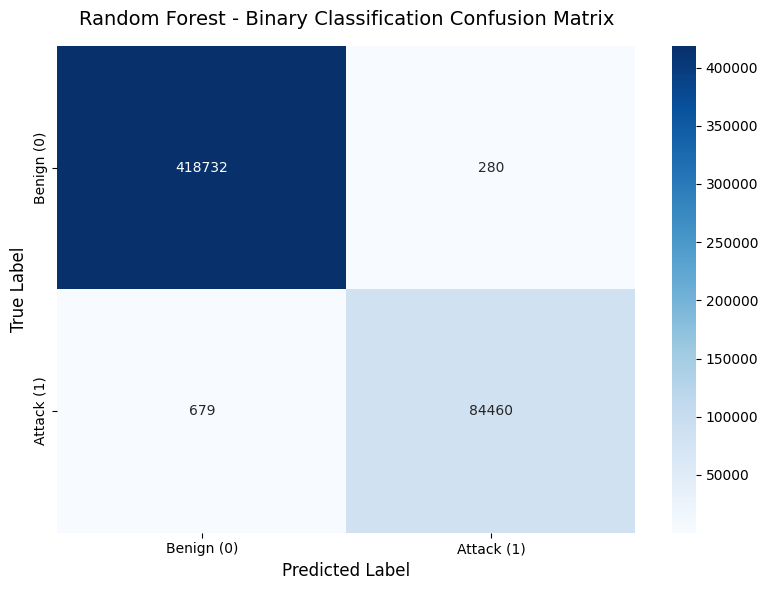

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# 1. Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred_rf)

# 2. Set up the figure size
plt.figure(figsize=(8, 6))

# 3. Create the heatmap
# fmt='d' ensures the numbers are displayed as whole integers (not scientific notation)
# cmap='Blues' gives it a clean, professional blue color scheme
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Benign (0)', 'Attack (1)'],
            yticklabels=['Benign (0)', 'Attack (1)'])

# 4. Add titles and labels
plt.title('Random Forest - Binary Classification Confusion Matrix', fontsize=14, pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)

# 5. Display the plot
plt.tight_layout()
plt.show()

--- Top 10 Most Important Features ---
                    Feature  Importance
     Packet Length Variance    0.124173
      Bwd Packet Length Max    0.105922
          Max Packet Length    0.104940
         Packet Length Mean    0.080681
Total Length of Fwd Packets    0.055079
               Flow IAT Std    0.041899
          Total Fwd Packets    0.039907
              Flow IAT Mean    0.033893
    Init_Win_bytes_backward    0.031120
      Fwd Packet Length Max    0.027684


/tmp/ipykernel_727/1004999964.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=top_10_features, palette='viridis')


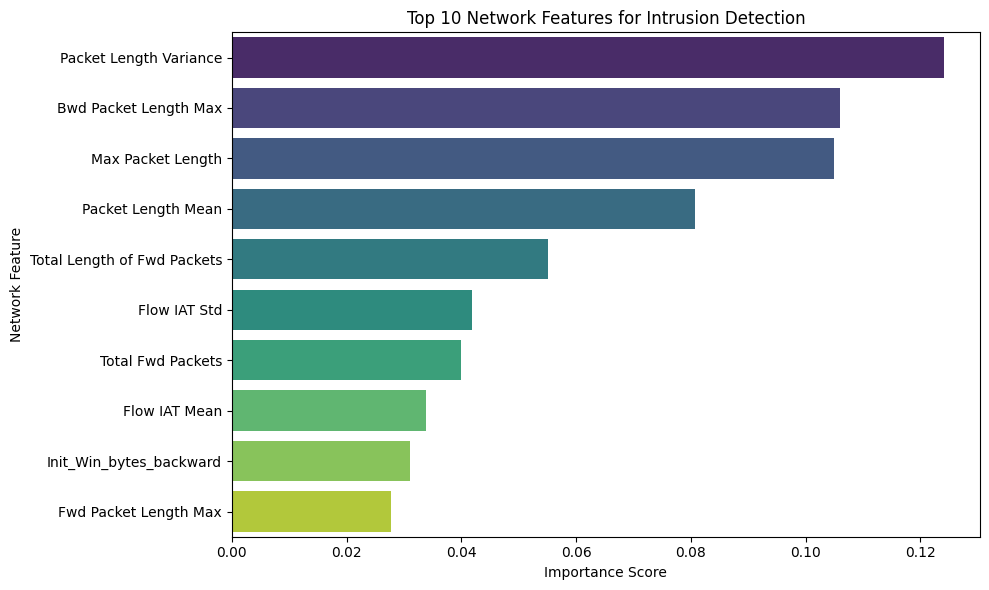

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract feature importances from the trained model
importances = rf_model.feature_importances_

# 2. Create a DataFrame to hold feature names and their importance scores
feature_names = X.columns
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# 3. Sort to get the top 10 features
top_10_features = feature_importance_df.sort_values(by='Importance', ascending=False).head(10)

# 4. Print the top 10 features
print("--- Top 10 Most Important Features ---")
print(top_10_features.to_string(index=False))

# 5. Plot the feature importances
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=top_10_features, palette='viridis')
plt.title('Top 10 Network Features for Intrusion Detection')
plt.xlabel('Importance Score')
plt.ylabel('Network Feature')
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# 1. Encode Multi-Class Labels (Benign, DDoS, DoS, etc.)
le = LabelEncoder()
# We use the original 'Attack Type' column from df, but the cleaned features from df_final
y_multi = le.fit_transform(df['Attack Type'])

# 2. Split the dataset (80% Training, 20% Testing)
# stratify=y_multi ensures all attack types are represented in both sets
X_train_mc, X_test_mc, y_train_mc, y_test_mc = train_test_split(
    df_final, y_multi, test_size=0.2, random_state=42, stratify=y_multi
)

print(f"Multi-Class Training set: {X_train_mc.shape[0]} samples")
print("-" * 40)

# 3. Train the Multi-Class Model
print("Training Multi-Class Random Forest Model... (This will take 1-2 minutes)")
rf_multi = RandomForestClassifier(n_estimators=50, max_depth=12, n_jobs=-1, random_state=42)
rf_multi.fit(X_train_mc, y_train_mc)

# 4. Make Predictions
y_pred_mc = rf_multi.predict(X_test_mc)

# 5. Evaluate the Model
print("\n--- Multi-Class Classification Report ---")
# target_names=le.classes_ puts the actual attack names (like 'DDoS') back into the report
print(classification_report(y_test_mc, y_pred_mc, target_names=le.classes_, digits=4))

Multi-Class Training set: 2016600 samples
----------------------------------------
Training Multi-Class Random Forest Model... (This will take 1-2 minutes)

--- Multi-Class Classification Report ---
                precision    recall  f1-score   support

          Bots     1.0000    0.0103    0.0204       389
   Brute Force     1.0000    0.9694    0.9845      1830
          DDoS     0.9995    0.9986    0.9990     25603
           DoS     0.9978    0.9807    0.9892     38749
Normal Traffic     0.9969    0.9993    0.9981    419012
 Port Scanning     0.9896    0.9988    0.9942     18139
   Web Attacks     1.0000    0.8322    0.9084       429

      accuracy                         0.9968    504151
     macro avg     0.9977    0.8270    0.8420    504151
  weighted avg     0.9968    0.9968    0.9964    504151



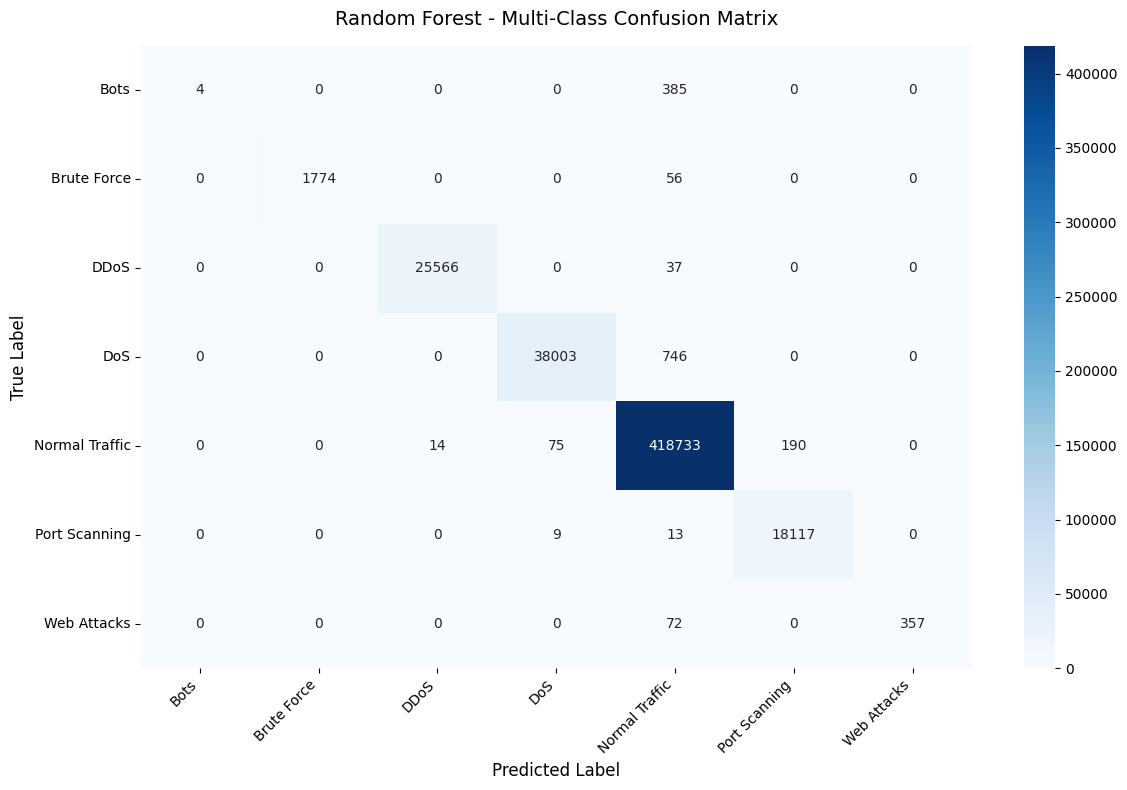

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

# 1. Generate the multi-class confusion matrix
cm_multi = confusion_matrix(y_test_mc, y_pred_mc)

# 2. Set up the figure size
plt.figure(figsize=(12, 8))

# 3. Create the heatmap (stray 'a' removed from here)
sns.heatmap(cm_multi, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_,
            yticklabels=le.classes_)

# 4. Add titles and labels
plt.title('Random Forest - Multi-Class Confusion Matrix', fontsize=14, pad=15)
plt.xlabel('Predicted Label', fontsize=12)
plt.ylabel('True Label', fontsize=12)

# 5. Display the plot
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import pandas as pd

# 1. Initialize ALL models directly in this block
models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1),
    "Logistic Regression": LogisticRegression(max_iter=1000, n_jobs=-1, random_state=42),
    "SVM (Linear)": LinearSVC(random_state=42, dual=False),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=15),
    "KNN": KNeighborsClassifier(n_jobs=-1)
}

results = []

# 2. Train and evaluate
print("Training models. This will take 5-10 minutes...")

for name, model in models.items():
    print(f"Processing {name}...")

    # Subset data for KNN to stop the 30+ minute freeze
    if name == "KNN":
        print("  -> Using a 50,000 row subset for KNN to prevent crashing...")
        X_train_sub, y_train_sub = X_train[:50000], y_train[:50000]
        X_test_sub, y_test_sub = X_test[:10000], y_test[:10000]

        model.fit(X_train_sub, y_train_sub)
        y_pred_model = model.predict(X_test_sub)
        acc = accuracy_score(y_test_sub, y_pred_model)
        precision, recall, f1, _ = precision_recall_fscore_support(y_test_sub, y_pred_model, average='binary', zero_division=0)

    else:
        # Full dataset for all other models
        model.fit(X_train, y_train)
        y_pred_model = model.predict(X_test)
        acc = accuracy_score(y_test, y_pred_model)
        precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred_model, average='binary', zero_division=0)

    results.append([name, round(acc, 4), round(precision, 4), round(recall, 4), round(f1, 4)])

# 3. Generate the required comparison table [cite: 113, 114]
results_df = pd.DataFrame(results, columns=["Model", "Accuracy", "Precision", "Recall", "F1-score"])
print("\n--- Model Comparison Table ---")
print(results_df.to_string(index=False))

Training models. This will take 5-10 minutes...
Processing Random Forest...
Processing Logistic Regression...
Processing SVM (Linear)...
Processing Decision Tree...
Processing KNN...
  -> Using a 50,000 row subset for KNN to prevent crashing...

--- Model Comparison Table ---
              Model  Accuracy  Precision  Recall  F1-score
      Random Forest    0.9981     0.9967  0.9920    0.9944
Logistic Regression    0.9411     0.8500  0.7906    0.8192
       SVM (Linear)    0.9452     0.8646  0.8010    0.8316
      Decision Tree    0.9987     0.9958  0.9966    0.9962
                KNN    0.9939     0.9783  0.9858    0.9820


In [ ]:
from sklearn.model_selection import cross_val_score
import pandas as pd
import numpy as np

print("Starting 10-Fold Cross-Validation (Task 2)...")
# We use a 50,000 row subset so the 10x training completes in 2-3 minutes
X_cv = X_train[:50000]
y_cv = y_train[:50000]

cv_models = {
    "Random Forest": models["Random Forest"],
    "SVM (Linear)": models["SVM (Linear)"]
}

cv_results = []

for name, model in cv_models.items():
    print(f"Running 10-Fold CV for {name}...")
    scores = cross_val_score(model, X_cv, y_cv, cv=10, scoring='accuracy', n_jobs=-1)
    cv_results.append([name, round(np.mean(scores), 4), round(np.std(scores), 4)])

cv_df = pd.DataFrame(cv_results, columns=["Model", "Mean Accuracy", "Std Deviation"])
print("\n--- 10-Fold Cross-Validation Results ---")
print(cv_df.to_string(index=False))

Starting 10-Fold Cross-Validation (Task 2)...
Running 10-Fold CV for Random Forest...
Running 10-Fold CV for SVM (Linear)...

--- 10-Fold Cross-Validation Results ---
        Model  Mean Accuracy  Std Deviation
Random Forest         0.9971         0.0009
 SVM (Linear)         0.9248         0.0035


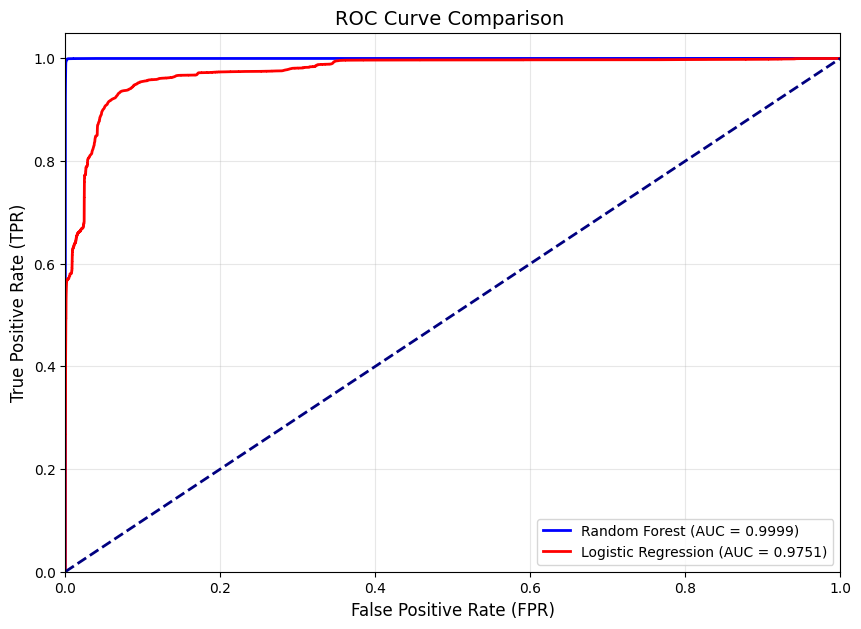

Random Forest AUC: 0.9999
Logistic Regression AUC: 0.9751


In [ ]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# 1. Get predicted probabilities for the 'Attack' class (class 1)
# Random Forest
y_probs_rf = models["Random Forest"].predict_proba(X_test)[:, 1]

# Logistic Regression
y_probs_lr = models["Logistic Regression"].predict_proba(X_test)[:, 1]

# 2. Calculate ROC curve data
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_probs_rf)
roc_auc_rf = auc(fpr_rf, tpr_rf)

fpr_lr, tpr_lr, _ = roc_curve(y_test, y_probs_lr)
roc_auc_lr = auc(fpr_lr, tpr_lr)

# 3. Plot the ROC Curve
plt.figure(figsize=(10, 7))
plt.plot(fpr_rf, tpr_rf, color='blue', lw=2, label=f'Random Forest (AUC = {roc_auc_rf:.4f})')
plt.plot(fpr_lr, tpr_lr, color='red', lw=2, label=f'Logistic Regression (AUC = {roc_auc_lr:.4f})')

# 4. Plot the 'Random Guess' baseline (diagonal line)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')

# 5. Formatting
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.title('ROC Curve Comparison ', fontsize=14)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

print(f"Random Forest AUC: {roc_auc_rf:.4f}")
print(f"Logistic Regression AUC: {roc_auc_lr:.4f}")

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 1. Get Feature Importances from your trained Random Forest
importances = models["Random Forest"].feature_importances_
feature_names = X_train.columns
feature_importance_df = pd.DataFrame({'Feature': feature_names, 'Importance': importances})
top_10_features = feature_importance_df.sort_values(by='Importance', ascending=False).head(10)['Feature'].tolist()

print("Top 10 Most Important Features identified:")
for i, feat in enumerate(top_10_features, 1):
    print(f"{i}. {feat}")

# 2. Train a "Lightweight" model using ONLY these 10 features
X_train_light = X_train[top_10_features]
X_test_light = X_test[top_10_features]

print("\nTraining Lightweight Random Forest (10 features)...")
rf_light = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf_light.fit(X_train_light, y_train)

# 3. Compare Results
y_pred_light = rf_light.predict(X_test_light)
acc_light = accuracy_score(y_test, y_pred_light)
acc_full = results_df[results_df['Model'] == 'Random Forest']['Accuracy'].values[0]

print("\n--- Feature Selection Comparison ---")
print(f"Full Model Accuracy (all features): {acc_full:.4f}")
print(f"Lightweight Model Accuracy (Top 10): {acc_light:.4f}")
print(f"Accuracy Drop: {round((acc_full - acc_light)*100, 4)}%")

Top 10 Most Important Features identified:
1. Packet Length Variance
2. Bwd Packet Length Max
3. Max Packet Length
4. Packet Length Mean
5. Total Length of Fwd Packets
6. Flow IAT Std
7. Total Fwd Packets
8. Flow IAT Mean
9. Init_Win_bytes_backward
10. Fwd Packet Length Max

Training Lightweight Random Forest (10 features)...

--- Feature Selection Comparison ---
Full Model Accuracy (all features): 0.9981
Lightweight Model Accuracy (Top 10): 0.9968
Accuracy Drop: 0.126%


Generating Precision-Recall Curve ...


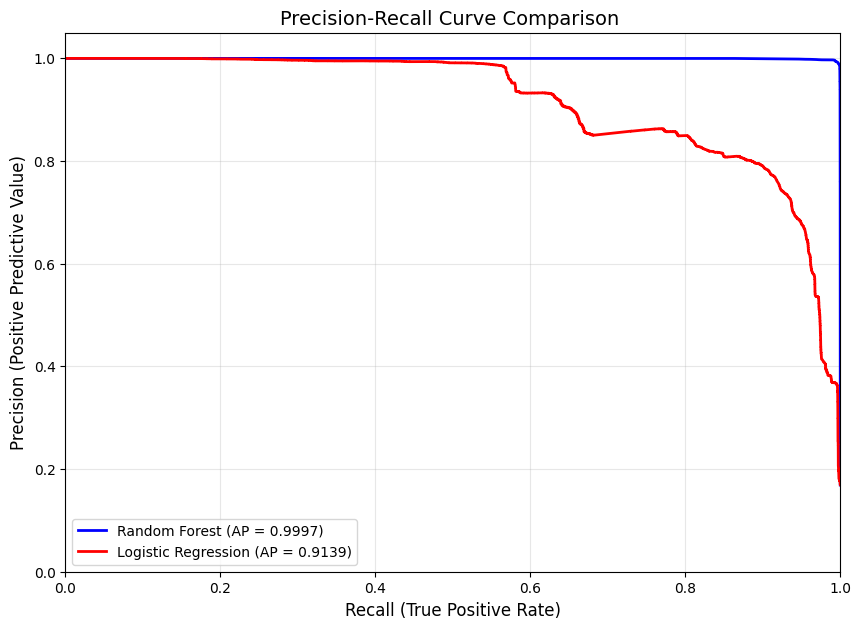

All tasks completed successfully!


In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

print("Generating Precision-Recall Curve ...")

# 1. Calculate Precision-Recall and Average Precision (AP) for Random Forest
precision_rf, recall_rf, _ = precision_recall_curve(y_test, y_probs_rf)
ap_rf = average_precision_score(y_test, y_probs_rf)

# 2. Calculate Precision-Recall and Average Precision (AP) for Logistic Regression
precision_lr, recall_lr, _ = precision_recall_curve(y_test, y_probs_lr)
ap_lr = average_precision_score(y_test, y_probs_lr)

# 3. Plot the Curves
plt.figure(figsize=(10, 7))
plt.plot(recall_rf, precision_rf, color='blue', lw=2, label=f'Random Forest (AP = {ap_rf:.4f})')
plt.plot(recall_lr, precision_lr, color='red', lw=2, label=f'Logistic Regression (AP = {ap_lr:.4f})')

# 4. Formatting
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Recall (True Positive Rate)', fontsize=12)
plt.ylabel('Precision (Positive Predictive Value)', fontsize=12)
plt.title('Precision-Recall Curve Comparison ', fontsize=14)
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.show()

print("All tasks completed successfully!")

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

print("--- TASK 5: Class Imbalance Check ---")

# 1. Print count of each class
print("Class Counts in Training Data:")
class_counts = pd.Series(y_train).value_counts()
print(class_counts)
print(f"\nPercentage:\n{(class_counts / len(y_train) * 100).round(2).astype(str)}%")

# 2. Train using class_weight='balanced'
print("\nTraining Random Forest with class_weight='balanced'...")
rf_balanced = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    random_state=42,
    class_weight='balanced', # This tells the model to pay more attention to the minority class
    n_jobs=-1
)
rf_balanced.fit(X_train, y_train)

# 3. Compare Results
y_pred_bal = rf_balanced.predict(X_test)
print("\n--- Balanced Model Results ---")
print(classification_report(y_test, y_pred_bal, digits=4))

--- TASK 5: Class Imbalance Check ---
Class Counts in Training Data:
Binary_Label
0    1676045
1     340555
Name: count, dtype: int64

Percentage:
Binary_Label
0    83.11
1    16.89
Name: count, dtype: object%

Training Random Forest with class_weight='balanced'...

--- Balanced Model Results ---
              precision    recall  f1-score   support

           0     0.9990    0.9988    0.9989    419012
           1     0.9939    0.9950    0.9945     85139

    accuracy                         0.9981    504151
   macro avg     0.9965    0.9969    0.9967    504151
weighted avg     0.9981    0.9981    0.9981    504151



In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

print("--- TASK 6: Hardest Attack to Detect ---")

# Generate the report as a dictionary so we can extract the lowest recall programmatically
report_dict = classification_report(y_test_mc, y_pred_mc, target_names=le.classes_, output_dict=True)

# Filter out 'accuracy', 'macro avg', 'weighted avg'
class_metrics = {k: v for k, v in report_dict.items() if k not in ['accuracy', 'macro avg', 'weighted avg']}

# Find the class with the lowest recall
lowest_recall_class = min(class_metrics, key=lambda k: class_metrics[k]['recall'])
lowest_recall_value = class_metrics[lowest_recall_class]['recall']

print(f"\nThe hardest attack to detect (Lowest Recall) is: ** {lowest_recall_class} **")
print(f"Recall Score: {lowest_recall_value:.4f} (meaning it only catches {lowest_recall_value*100:.2f}% of these attacks)")

print("\nDiscussion Point for your Report:")
print(f"The model struggles most with {lowest_recall_class}. This is typically because this attack type has very few samples in the dataset compared to DDoS or PortScan, or its network footprint looks nearly identical to Benign traffic.")

--- TASK 6: Hardest Attack to Detect ---

The hardest attack to detect (Lowest Recall) is: ** Bots **
Recall Score: 0.0103 (meaning it only catches 1.03% of these attacks)

Discussion Point for your Report:
The model struggles most with Bots. This is typically because this attack type has very few samples in the dataset compared to DDoS or PortScan, or its network footprint looks nearly identical to Benign traffic.


In [ ]:
import time
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

# 1. Setup 50k subset for fast time measurement
X_train_time = X_train[:50000]
y_train_time = y_train[:50000]
X_test_time = X_test[:10000]

# 2. Initialize models
models_time = {
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1),
    "Logistic Regression": LogisticRegression(max_iter=1000, n_jobs=-1, random_state=42),
    "SVM (Linear)": LinearSVC(random_state=42, dual=False),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=15),
    "KNN": KNeighborsClassifier(n_jobs=-1)
}

time_results = []

print("Running Task 7: Computational Time Analysis...")

# 3. Measure times
for name, model in models_time.items():
    # Measure Training Time
    start_train = time.time()
    model.fit(X_train_time, y_train_time)
    train_time = round(time.time() - start_train, 4)

    # Measure Prediction Time
    start_pred = time.time()
    model.predict(X_test_time)
    pred_time = round(time.time() - start_pred, 4)

    time_results.append([name, train_time, pred_time])

# 4. Generate the required table
time_df = pd.DataFrame(time_results, columns=["Model", "Training Time (s)", "Prediction Time (s)"])
print("\n--- Task 7: Computational Time Analysis ---")
print(time_df.to_string(index=False))

Running Task 7: Computational Time Analysis...

--- Task 7: Computational Time Analysis ---
              Model  Training Time (s)  Prediction Time (s)
      Random Forest            11.0886               0.0863
Logistic Regression             2.4753               0.0035
       SVM (Linear)             2.2671               0.0031
      Decision Tree             1.5619               0.0038
                KNN             0.0200               3.7192


--- Task 8: Result Visualizations ---


/tmp/ipykernel_727/1739117566.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Model', y='Accuracy', data=results_df, palette='viridis')


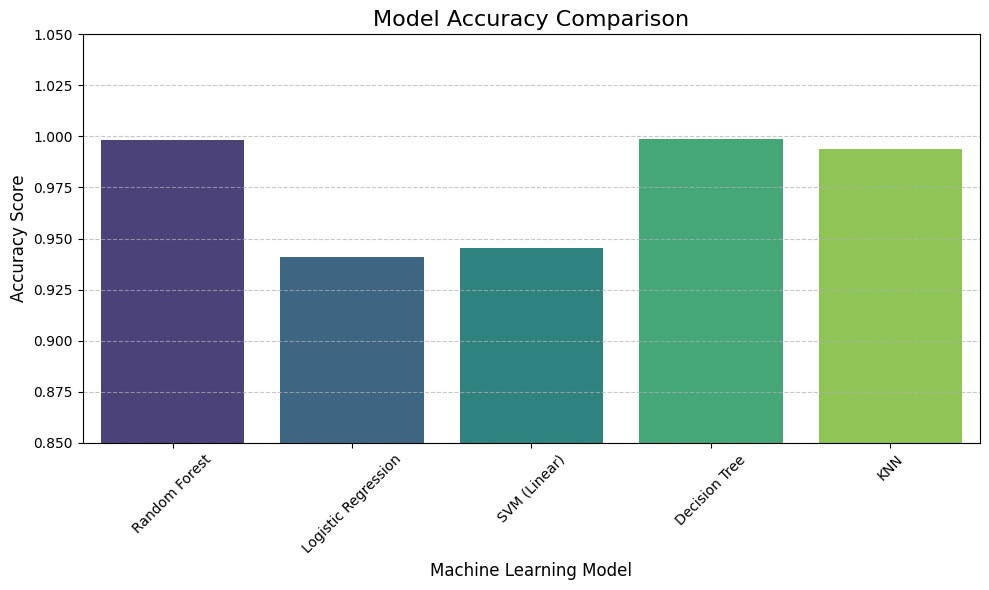

/tmp/ipykernel_727/1739117566.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=top_15_df, palette='magma')


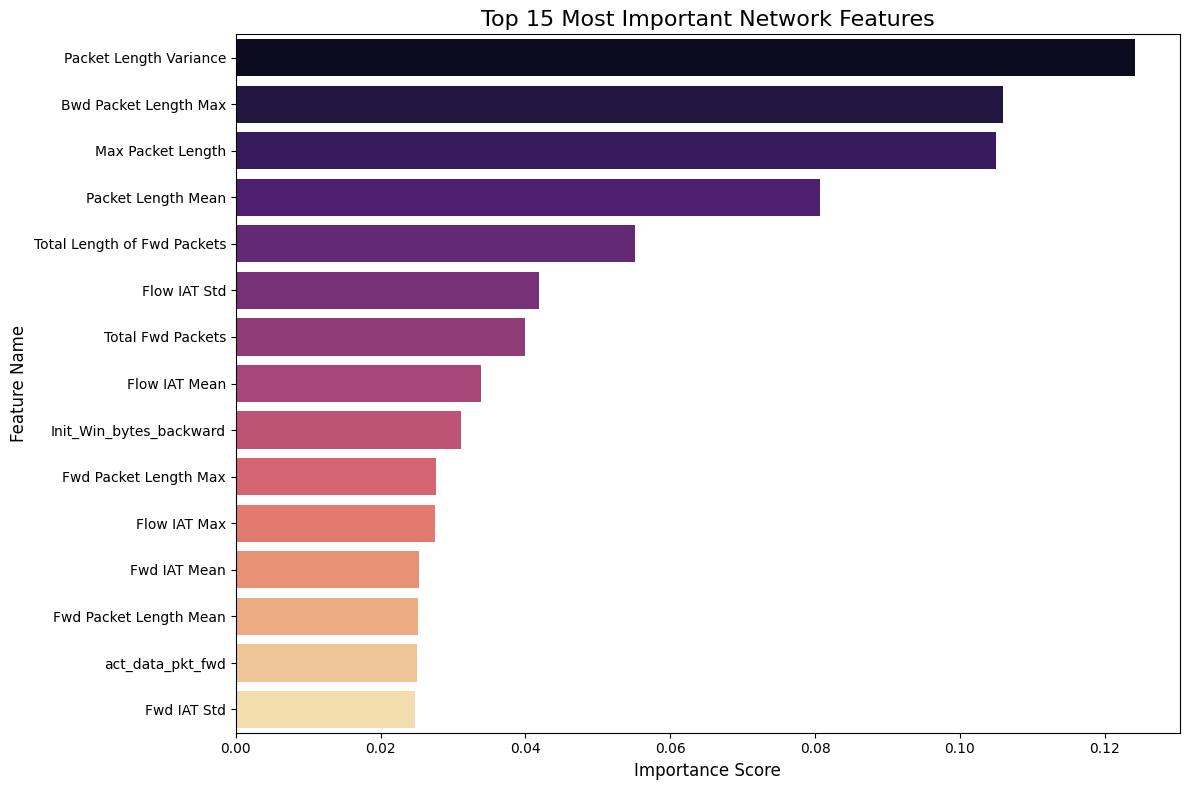

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("--- Task 8: Result Visualizations ---")

# 1. Bar Chart Comparing Models (Accuracy)
plt.figure(figsize=(10, 6))
# Using the results_df from Task 1
sns.barplot(x='Model', y='Accuracy', data=results_df, palette='viridis')
plt.title('Model Accuracy Comparison', fontsize=16)
plt.ylim(0.85, 1.05) # Zoom in slightly to see the differences clearly
plt.ylabel('Accuracy Score', fontsize=12)
plt.xlabel('Machine Learning Model', fontsize=12)
plt.xticks(rotation=45)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 2. Feature Importance Bar Graph (Top 15)
# Getting the top 15 as explicitly requested by your document
top_15_df = feature_importance_df.sort_values(by='Importance', ascending=False).head(15)

plt.figure(figsize=(12, 8))
sns.barplot(x='Importance', y='Feature', data=top_15_df, palette='magma')
plt.title('Top 15 Most Important Network Features', fontsize=16)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Feature Name', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score

# --- TASK 1: FIX DATA LEAKAGE ---
# 1. Split the data FIRST (assuming X and y are already defined from your preprocessing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Fit the scaler ONLY on training data, then transform both
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# --- TASK 2: FINAL MODEL COMPARISON ---
# Initialize models (Replaced KNN with Naive Bayes to prevent memory crashes on full dataset)
models = {
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1),
    "Logistic Regression": LogisticRegression(max_iter=1000, n_jobs=-1, random_state=42),
    "SVM (Linear)": LinearSVC(random_state=42, dual=False),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=15),
    "Naive Bayes": GaussianNB()
}

results = []

print("Training models and computing metrics (This will take a few minutes)...\n")

for name, model in models.items():
    print(f"Processing {name}...")

    # Train using correctly scaled data
    model.fit(X_train_scaled, y_train)

    # Predict
    y_pred = model.predict(X_test_scaled)

    # Extract scores for AUC
    if hasattr(model, "predict_proba"):
        y_scores = model.predict_proba(X_test_scaled)[:, 1]
    else:
        y_scores = model.decision_function(X_test_scaled)

    # Calculate metrics targeting the 'Attack' class (pos_label=1)
    acc = accuracy_score(y_test, y_pred)
    prec_attack = precision_score(y_test, y_pred, pos_label=1, zero_division=0)
    rec_attack = recall_score(y_test, y_pred, pos_label=1, zero_division=0)
    f1_attack = f1_score(y_test, y_pred, pos_label=1, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_scores)
    pr_auc = average_precision_score(y_test, y_scores)

    # Store results
    results.append({
        "Model": name,
        "Acc": round(acc, 4),
        "Prec(Attack)": round(prec_attack, 4),
        "Rec(Attack)": round(rec_attack, 4),
        "F1(Attack)": round(f1_attack, 4),
        "ROC-AUC": round(roc_auc, 4),
        "PR-AUC": round(pr_auc, 4)
    })

# [cite_start]Generate and display Table 1 [cite: 229, 230, 231]
df_results = pd.DataFrame(results)
print("\n--- Table 1: Binary Classification Final Model Comparison ---")
print(df_results.to_string(index=False))

Training models and computing metrics (This will take a few minutes)...

Processing Random Forest...
Processing Logistic Regression...
Processing SVM (Linear)...
Processing Decision Tree...
Processing Naive Bayes...

--- Table 1: Binary Classification Final Model Comparison ---
              Model    Acc  Prec(Attack)  Rec(Attack)  F1(Attack)  ROC-AUC  PR-AUC
      Random Forest 0.9981        0.9967       0.9920      0.9944   0.9999  0.9997
Logistic Regression 0.9415        0.8527       0.7902      0.8203   0.9748  0.9135
       SVM (Linear) 0.9452        0.8646       0.8010      0.8316   0.9738  0.9172
      Decision Tree 0.9987        0.9958       0.9966      0.9962   0.9997  0.9988
        Naive Bayes 0.5913        0.2904       0.9841      0.4485   0.9032  0.6599


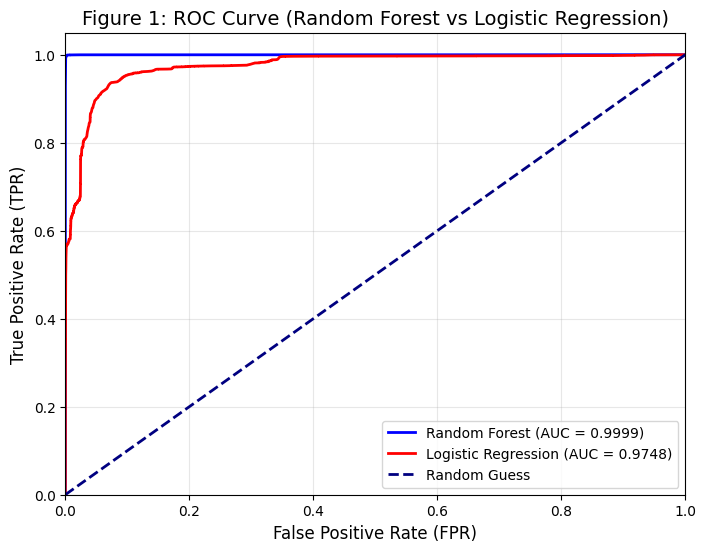

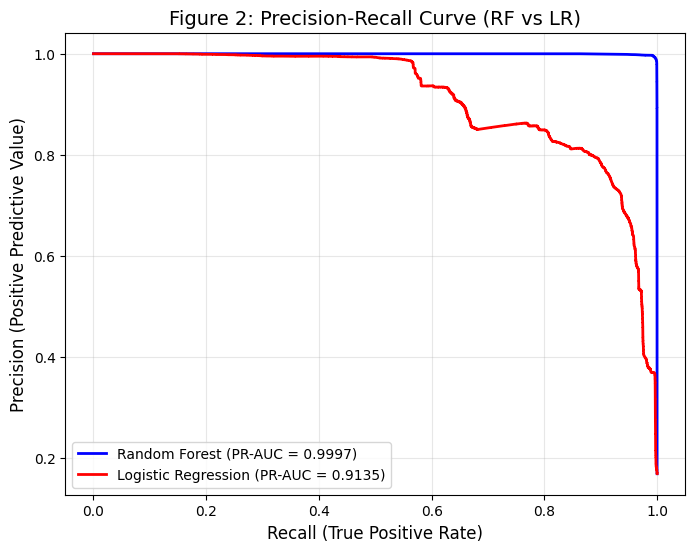

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, precision_recall_curve, roc_auc_score, average_precision_score

# 1. Extract the trained models from your existing 'models' dictionary
rf_model = models["Random Forest"]
lr_model = models["Logistic Regression"]

# 2. Get predicted probabilities for the 'Attack' class (class 1)
rf_probs = rf_model.predict_proba(X_test_scaled)[:, 1]
lr_probs = lr_model.predict_proba(X_test_scaled)[:, 1]

# --- FIGURE 1: ROC CURVE ---
# Calculate False Positive Rate (FPR) and True Positive Rate (TPR)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probs)
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probs)

# Get AUC scores
rf_roc_auc = roc_auc_score(y_test, rf_probs)
lr_roc_auc = roc_auc_score(y_test, lr_probs)

plt.figure(figsize=(8, 6))
plt.plot(rf_fpr, rf_tpr, color='blue', lw=2, label=f'Random Forest (AUC = {rf_roc_auc:.4f})')
plt.plot(lr_fpr, lr_tpr, color='red', lw=2, label=f'Logistic Regression (AUC = {lr_roc_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guess')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)', fontsize=12)
plt.ylabel('True Positive Rate (TPR)', fontsize=12)
plt.title('Figure 1: ROC Curve (Random Forest vs Logistic Regression)', fontsize=14)
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

# --- FIGURE 2: PR CURVE ---
# Calculate Precision and Recall values across different thresholds
rf_precision, rf_recall, _ = precision_recall_curve(y_test, rf_probs)
lr_precision, lr_recall, _ = precision_recall_curve(y_test, lr_probs)

# Calculate Average Precision (PR-AUC)
rf_pr_auc = average_precision_score(y_test, rf_probs)
lr_pr_auc = average_precision_score(y_test, lr_probs)

plt.figure(figsize=(8, 6))
plt.plot(rf_recall, rf_precision, color='blue', lw=2, label=f'Random Forest (PR-AUC = {rf_pr_auc:.4f})')
plt.plot(lr_recall, lr_precision, color='red', lw=2, label=f'Logistic Regression (PR-AUC = {lr_pr_auc:.4f})')
plt.xlabel('Recall (True Positive Rate)', fontsize=12)
plt.ylabel('Precision (Positive Predictive Value)', fontsize=12)
plt.title('Figure 2: Precision-Recall Curve (RF vs LR)', fontsize=14)
plt.legend(loc="lower left")
plt.grid(alpha=0.3)
plt.show()


--- Table 2: Threshold Tuning Results ---
              Model  Default (0.5) F1(A)  Best Threshold  Best F1(A)  Precision(A)  Recall(A)
      Random Forest               0.9944            0.45      0.9944        0.9964     0.9925
Logistic Regression               0.8203            0.20      0.8404        0.7941     0.8923


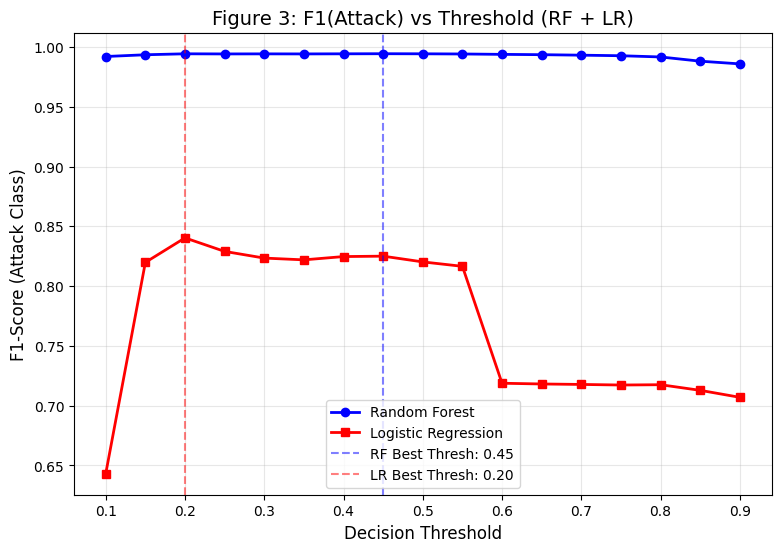

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score, f1_score

# 1. Define thresholds: 0.1 to 0.9 with step 0.05
thresholds = np.arange(0.1, 0.95, 0.05)

rf_f1_scores = []
lr_f1_scores = []

# Dictionaries to track the best performing threshold metrics
best_rf = {'thresh': 0.5, 'f1': 0, 'prec': 0, 'rec': 0, 'default_f1': 0}
best_lr = {'thresh': 0.5, 'f1': 0, 'prec': 0, 'rec': 0, 'default_f1': 0}

# 2. Get baseline Default (0.5) F1 scores
y_pred_rf_default = (rf_probs >= 0.5).astype(int)
y_pred_lr_default = (lr_probs >= 0.5).astype(int)

best_rf['default_f1'] = f1_score(y_test, y_pred_rf_default, pos_label=1, zero_division=0)
best_lr['default_f1'] = f1_score(y_test, y_pred_lr_default, pos_label=1, zero_division=0)

# 3. Sweep through thresholds
for t in thresholds:
    # Convert probabilities to binary predictions based on threshold 't'
    y_pred_rf_t = (rf_probs >= t).astype(int)
    y_pred_lr_t = (lr_probs >= t).astype(int)

    # Calculate F1(Attack)
    f1_rf = f1_score(y_test, y_pred_rf_t, pos_label=1, zero_division=0)
    f1_lr = f1_score(y_test, y_pred_lr_t, pos_label=1, zero_division=0)

    rf_f1_scores.append(f1_rf)
    lr_f1_scores.append(f1_lr)

    # Update best metrics for Random Forest
    if f1_rf > best_rf['f1']:
        best_rf.update({
            'thresh': t,
            'f1': f1_rf,
            'prec': precision_score(y_test, y_pred_rf_t, pos_label=1, zero_division=0),
            'rec': recall_score(y_test, y_pred_rf_t, pos_label=1, zero_division=0)
        })

    # Update best metrics for Logistic Regression
    if f1_lr > best_lr['f1']:
        best_lr.update({
            'thresh': t,
            'f1': f1_lr,
            'prec': precision_score(y_test, y_pred_lr_t, pos_label=1, zero_division=0),
            'rec': recall_score(y_test, y_pred_lr_t, pos_label=1, zero_division=0)
        })

# --- DELIVERABLE: Table 2 ---
table2_data = [
    {"Model": "Random Forest", "Default (0.5) F1(A)": round(best_rf['default_f1'], 4), "Best Threshold": round(best_rf['thresh'], 2), "Best F1(A)": round(best_rf['f1'], 4), "Precision(A)": round(best_rf['prec'], 4), "Recall(A)": round(best_rf['rec'], 4)},
    {"Model": "Logistic Regression", "Default (0.5) F1(A)": round(best_lr['default_f1'], 4), "Best Threshold": round(best_lr['thresh'], 2), "Best F1(A)": round(best_lr['f1'], 4), "Precision(A)": round(best_lr['prec'], 4), "Recall(A)": round(best_lr['rec'], 4)}
]

df_table2 = pd.DataFrame(table2_data)
print("\n--- Table 2: Threshold Tuning Results ---")
print(df_table2.to_string(index=False))

# --- DELIVERABLE: Figure 3 ---
plt.figure(figsize=(9, 6))
plt.plot(thresholds, rf_f1_scores, marker='o', color='blue', lw=2, label='Random Forest')
plt.plot(thresholds, lr_f1_scores, marker='s', color='red', lw=2, label='Logistic Regression')

# Add vertical lines to show where the maximum F1 occurs
plt.axvline(x=best_rf['thresh'], color='blue', linestyle='--', alpha=0.5, label=f"RF Best Thresh: {best_rf['thresh']:.2f}")
plt.axvline(x=best_lr['thresh'], color='red', linestyle='--', alpha=0.5, label=f"LR Best Thresh: {best_lr['thresh']:.2f}")

plt.xlabel('Decision Threshold', fontsize=12)
plt.ylabel('F1-Score (Attack Class)', fontsize=12)
plt.title('Figure 3: F1(Attack) vs Threshold (RF + LR)', fontsize=14)
plt.xticks(np.arange(0.1, 1.0, 0.1))
plt.legend(loc="lower center")
plt.grid(alpha=0.3)
plt.show()

In [ ]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, average_precision_score

print("Training base Random Forest to get feature importances (this ensures no NameErrors!)...")

# --- FIX: Train a fresh Random Forest right here to guarantee it exists in memory ---
rf_base = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf_base.fit(X_train_scaled, y_train)

# 1. Get feature importances
importances = rf_base.feature_importances_

# Create a DataFrame to sort and get top feature indices
feat_imp_df = pd.DataFrame({'Feature': X.columns, 'Importance': importances})
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

# Extract the column indices for the top features
top_20_features_idx = feat_imp_df.head(20).index.tolist()
top_10_features_idx = feat_imp_df.head(10).index.tolist()

# Define the feature sets we want to test
num_features = X_train_scaled.shape[1]
feature_sets = {
    'All Features': list(range(num_features)),
    'Top-20': top_20_features_idx,
    'Top-10': top_10_features_idx
}

ablation_results = []

print("Running Feature Ablation Experiments (Training 3 models)...\n")

# 2. Train and evaluate models on different feature subsets
for name, feature_idx in feature_sets.items():
    print(f"Evaluating '{name}'...")

    # Safely subset the data whether it's a pandas DataFrame or a numpy array
    if isinstance(X_train_scaled, np.ndarray):
        X_train_sub = X_train_scaled[:, feature_idx]
        X_test_sub = X_test_scaled[:, feature_idx]
    else:
        X_train_sub = X_train_scaled.iloc[:, feature_idx]
        X_test_sub = X_test_scaled.iloc[:, feature_idx]

    # Initialize model
    model = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)

    # Measure Training Time
    start_train = time.time()
    model.fit(X_train_sub, y_train)
    train_time = round(time.time() - start_train, 4)

    # Measure Prediction Time
    start_pred = time.time()
    y_pred = model.predict(X_test_sub)
    y_probs = model.predict_proba(X_test_sub)[:, 1] # Get probabilities for attack class
    pred_time = round(time.time() - start_pred, 4)

    # Calculate Metrics
    f1_atk = f1_score(y_test, y_pred, pos_label=1, zero_division=0)
    pr_auc = average_precision_score(y_test, y_probs)

    # Store
    ablation_results.append({
        "Feature Set": name,
        "# Features": len(feature_idx),
        "F1(Attack)": round(f1_atk, 4),
        "PR-AUC": round(pr_auc, 4),
        "Train Time(s)": train_time,
        "Predict Time(s)": pred_time
    })

# --- DELIVERABLE: Table 3 ---
df_table3 = pd.DataFrame(ablation_results)
print("\n--- Table 3: Feature Ablation (Lightweight IDS) ---")
print(df_table3.to_string(index=False))

Training base Random Forest to get feature importances (this ensures no NameErrors!)...
Running Feature Ablation Experiments (Training 3 models)...

Evaluating 'All Features'...
Evaluating 'Top-20'...
Evaluating 'Top-10'...

--- Table 3: Feature Ablation (Lightweight IDS) ---
 Feature Set  # Features  F1(Attack)  PR-AUC  Train Time(s)  Predict Time(s)
All Features          39      0.9944  0.9997      1107.6272           9.9937
      Top-20          20      0.9945  0.9997       732.1513           9.2709
      Top-10          10      0.9906  0.9993       637.5471           7.4902


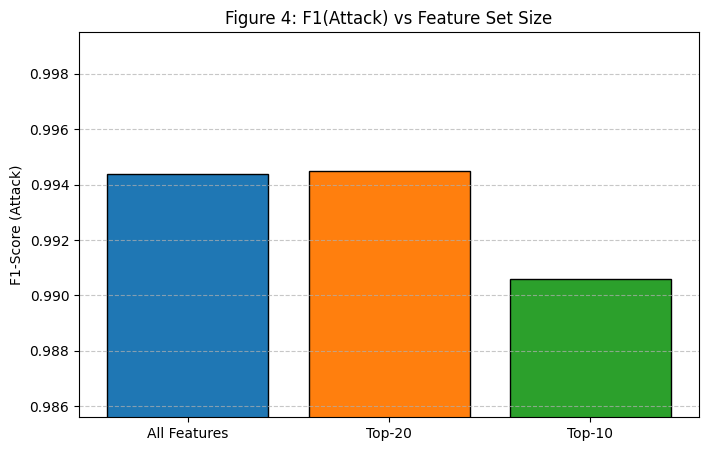

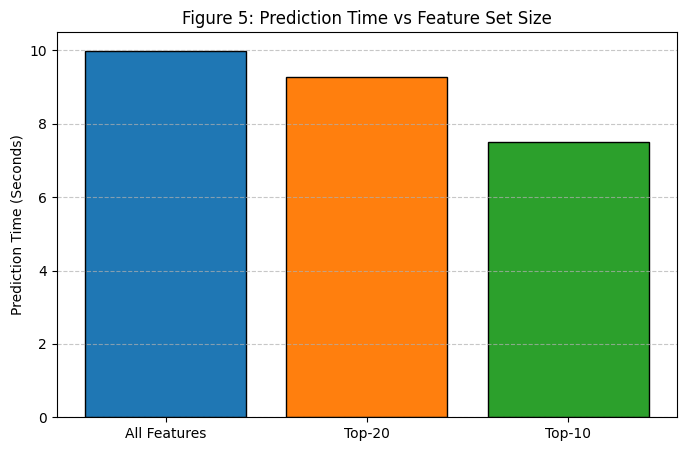


Running 10-Fold Cross-Validation on a 50k subset...
Evaluating Random Forest...
Evaluating Logistic Regression...

--- Table 6: 10-Fold Cross Validation Results ---
              Model  Mean Acc  Std Acc  Mean F1(A)  Std F1(A)
      Random Forest    0.9972   0.0010      0.9917     0.0029
Logistic Regression    0.9206   0.0032      0.7114     0.0146


In [ ]:
# --- DELIVERABLES: Figure 4 & Figure 5 (Ablation Bar Charts) ---
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_validate
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# Use the data from the df_table3 you just generated
feature_sets = df_table3['Feature Set']
f1_scores = df_table3['F1(Attack)']
pred_times = df_table3['Predict Time(s)']

# Figure 4: F1 Attack vs Feature Set Size
plt.figure(figsize=(8, 5))
plt.bar(feature_sets, f1_scores, color=['#1f77b4', '#ff7f0e', '#2ca02c'], edgecolor='black')
plt.title('Figure 4: F1(Attack) vs Feature Set Size')
plt.ylabel('F1-Score (Attack)')
# Zooming in the Y-axis to make the tiny differences visible
plt.ylim(min(f1_scores) - 0.005, max(f1_scores) + 0.005)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# Figure 5: Prediction Time vs Feature Set Size
plt.figure(figsize=(8, 5))
plt.bar(feature_sets, pred_times, color=['#1f77b4', '#ff7f0e', '#2ca02c'], edgecolor='black')
plt.title('Figure 5: Prediction Time vs Feature Set Size')
plt.ylabel('Prediction Time (Seconds)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


# =====================================================================
# --- DELIVERABLE: Table 6 (10-Fold Cross Validation) ---
# =====================================================================

print("\nRunning 10-Fold Cross-Validation on a 50k subset...")

# Subsample for CV to save time (50,000 rows as per instructions)
CV_LIMIT = 50000
if isinstance(X_train_scaled, np.ndarray):
    X_cv = X_train_scaled[:CV_LIMIT]
    y_cv = y_train[:CV_LIMIT]
else:
    X_cv = X_train_scaled.iloc[:CV_LIMIT]
    y_cv = y_train.iloc[:CV_LIMIT]

cv_models = {
    "Random Forest": RandomForestClassifier(n_estimators=50, max_depth=15, random_state=42, n_jobs=-1),
    "Logistic Regression": LogisticRegression(max_iter=1000, n_jobs=-1, random_state=42)
}

cv_results_list = []
scoring = {'acc': 'accuracy', 'f1': 'f1'}

for name, model in cv_models.items():
    print(f"Evaluating {name}...")
    # Perform 10-fold cross validation
    scores = cross_validate(model, X_cv, y_cv, cv=10, scoring=scoring, n_jobs=-1)

    cv_results_list.append({
        "Model": name,
        "Mean Acc": round(np.mean(scores['test_acc']), 4),
        "Std Acc": round(np.std(scores['test_acc']), 4),
        "Mean F1(A)": round(np.mean(scores['test_f1']), 4),
        "Std F1(A)": round(np.std(scores['test_f1']), 4)
    })

df_table6 = pd.DataFrame(cv_results_list)
print("\n--- Table 6: 10-Fold Cross Validation Results ---")
print(df_table6.to_string(index=False))

In [ ]:
print(df.columns[-10:].tolist())

['act_data_pkt_fwd', 'min_seg_size_forward', 'Active Mean', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Max', 'Idle Min', 'Attack Type', 'Binary_Label']


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

# 1. Split the data (assuming X and y are already defined from your dataset load)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Fit the scaler ONLY on the training data to prevent data leakage
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score

In [ ]:
# --- IMPORT FIX ---
from sklearn.metrics import precision_score, recall_score, f1_score, average_precision_score
from sklearn.model_selection import train_test_split
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

print("\n--- Optimizing Data for Imbalance Study ---")
# Take a 20% stratified sample of the training data to prevent Colab from freezing
X_train_sub, _, y_train_sub, _ = train_test_split(
    X_train_scaled, y_train, train_size=0.2, random_state=42, stratify=y_train
)

print("\n--- Class Distribution (20% Subset) ---")
class_counts = y_train_sub.value_counts()
print(f"Benign (0): {class_counts[0]} ({class_counts[0]/len(y_train_sub)*100:.2f}%)")
print(f"Attack (1): {class_counts[1]} ({class_counts[1]/len(y_train_sub)*100:.2f}%)")

print("\nTraining Baseline Model...")
# Changed n_jobs to 2 to prevent Colab CPU deadlocks
rf_base = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=2)
rf_base.fit(X_train_sub, y_train_sub)
y_pred_base = rf_base.predict(X_test_scaled)
y_prob_base = rf_base.predict_proba(X_test_scaled)[:, 1]

print("Training Balanced Model...")
rf_balanced = RandomForestClassifier(n_estimators=100, max_depth=15, class_weight='balanced', random_state=42, n_jobs=2)
rf_balanced.fit(X_train_sub, y_train_sub)
y_pred_bal = rf_balanced.predict(X_test_scaled)
y_prob_bal = rf_balanced.predict_proba(X_test_scaled)[:, 1]

# Calculate Metrics
def get_imbalance_metrics(y_true, y_pred, y_prob):
    prec = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
    rec = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
    f1 = f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    pr_auc = average_precision_score(y_true, y_prob)
    return [prec, rec, f1, pr_auc]

base_metrics = get_imbalance_metrics(y_test, y_pred_base, y_prob_base)
bal_metrics = get_imbalance_metrics(y_test, y_pred_bal, y_prob_bal)

# Create Deliverable: Table 4
table4_data = [
    ["Baseline (No Balancing)"] + base_metrics,
    ["RF (class_weight='balanced')"] + bal_metrics
]

df_table4 = pd.DataFrame(table4_data, columns=["Method", "Prec(A)", "Rec(A)", "F1(A)", "PR-AUC"])

print("\n--- Deliverable: Table 4 (Class Imbalance Study) ---")
print(df_table4.round(4).to_string(index=False))


--- Optimizing Data for Imbalance Study ---

--- Class Distribution (20% Subset) ---
Benign (0): 335209 (83.11%)
Attack (1): 68111 (16.89%)

Training Baseline Model...
Training Balanced Model...

--- Deliverable: Table 4 (Class Imbalance Study) ---
                      Method  Prec(A)  Rec(A)  F1(A)  PR-AUC
     Baseline (No Balancing)   0.9965  0.9913 0.9939  0.9996
RF (class_weight='balanced')   0.9944  0.9943 0.9943  0.9996


Preparing Multi-Class Data...
Training Multi-Class Random Forest (This might take about 1 minute)...

--- Deliverable: Table 5 ---
        Model    Acc  Macro-F1  Weighted-F1
Random Forest 0.9979    0.9131       0.9978


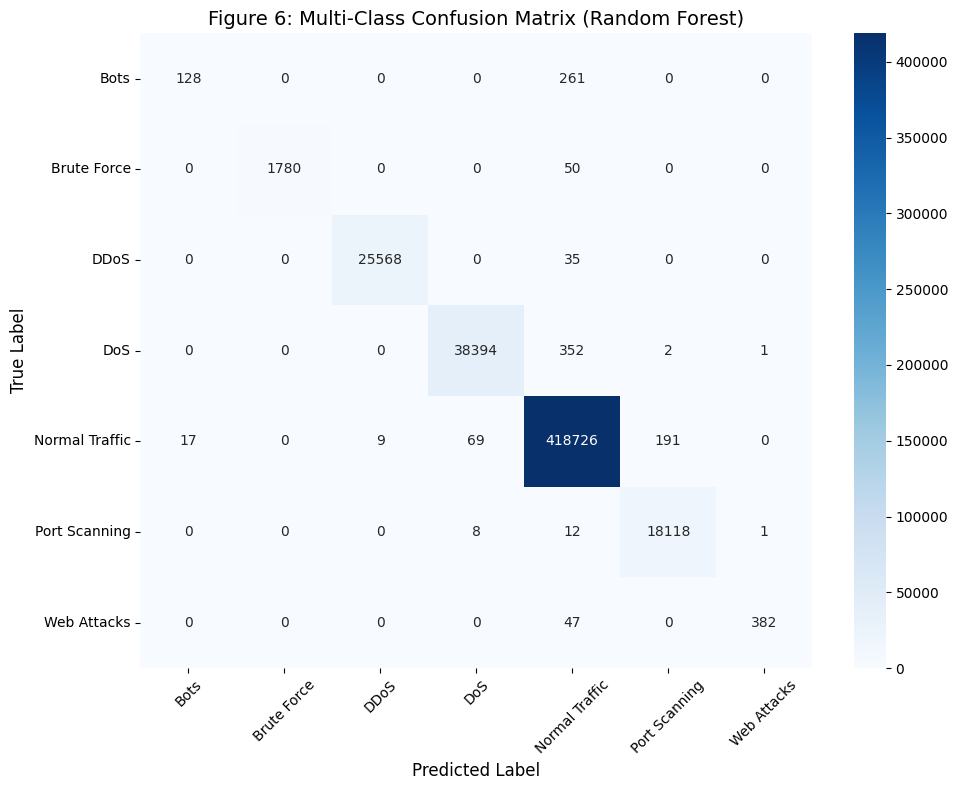


Generating Hardest Attack Type Analysis...


/tmp/ipykernel_52685/3579548706.py:67: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=recalls, y=class_names, palette="viridis")


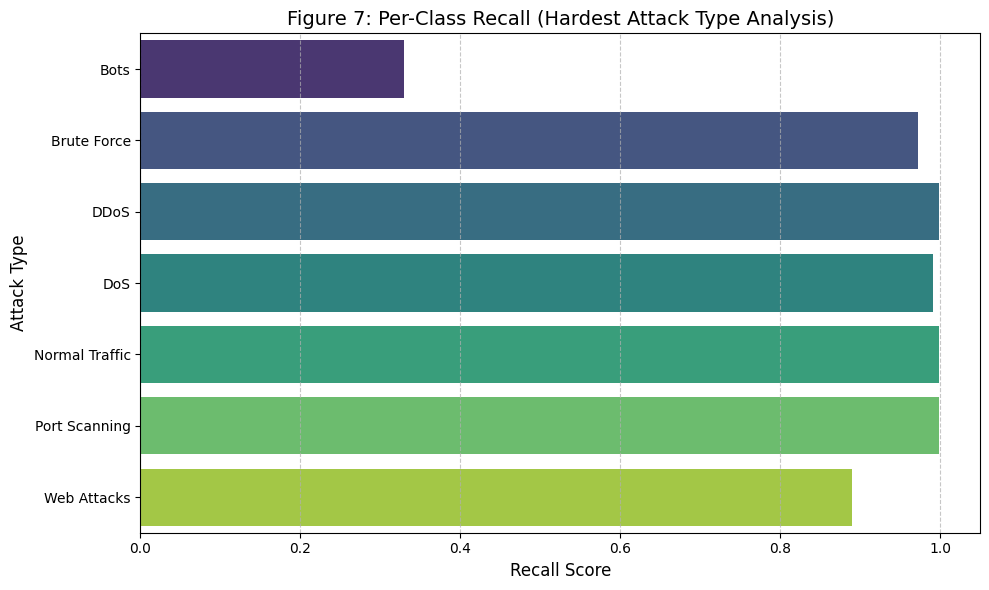


--- Discussion ---
Which attack is hardest to detect? -> **Bots** (Recall: 0.3290)
Look at Figure 6 to see which class it is being confused with the most!


In [ ]:
# --- TASK 7 & 8: MULTI-CLASS EXPERIMENTS & HARDEST ATTACK ---
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

print("Preparing Multi-Class Data...")
# Encode the multi-class labels - FIXED: using 'df' instead of 'df_final'
le = LabelEncoder()
y_multi = le.fit_transform(df['Attack Type'])

# 1. Split the data
X_train_m, X_test_m, y_train_m, y_test_m = train_test_split(X, y_multi, test_size=0.2, random_state=42, stratify=y_multi)

# 2. Optimize: Take a 30% subset of the training data to prevent Colab from freezing
X_train_m_sub, _, y_train_m_sub, _ = train_test_split(X_train_m, y_train_m, train_size=0.3, random_state=42, stratify=y_train_m)

# 3. Fix Data Leakage: Fit scaler ONLY on the train subset, transform both
scaler_m = MinMaxScaler()
X_train_m_scaled = scaler_m.fit_transform(X_train_m_sub)
X_test_m_scaled = scaler_m.transform(X_test_m)

print("Training Multi-Class Random Forest (This might take about 1 minute)...")
rf_multi = RandomForestClassifier(n_estimators=100, max_depth=15, random_state=42, n_jobs=2)
rf_multi.fit(X_train_m_scaled, y_train_m_sub)
y_pred_m = rf_multi.predict(X_test_m_scaled)

# --- Deliverable: Table 5 (Multi-Class Performance) ---
acc_m = accuracy_score(y_test_m, y_pred_m)
macro_f1 = f1_score(y_test_m, y_pred_m, average='macro')
weighted_f1 = f1_score(y_test_m, y_pred_m, average='weighted')

df_table5 = pd.DataFrame([["Random Forest", acc_m, macro_f1, weighted_f1]],
                         columns=["Model", "Acc", "Macro-F1", "Weighted-F1"])
print("\n--- Deliverable: Table 5 ---")
print(df_table5.round(4).to_string(index=False))

# --- Deliverable: Figure 6 (Confusion Matrix) ---
cm_multi = confusion_matrix(y_test_m, y_pred_m)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_multi, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("Figure 6: Multi-Class Confusion Matrix (Random Forest)", fontsize=14)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- Deliverable: Task 8 (Hardest Attack Type Analysis) ---
print("\nGenerating Hardest Attack Type Analysis...")
report_dict = classification_report(y_test_m, y_pred_m, target_names=le.classes_, output_dict=True, zero_division=0)

class_names = []
recalls = []
for class_name in le.classes_:
    if class_name in report_dict:
        class_names.append(class_name)
        recalls.append(report_dict[class_name]['recall'])

# --- Deliverable: Figure 7 ---
plt.figure(figsize=(10, 6))
sns.barplot(x=recalls, y=class_names, palette="viridis")
plt.title("Figure 7: Per-Class Recall (Hardest Attack Type Analysis)", fontsize=14)
plt.xlabel("Recall Score", fontsize=12)
plt.ylabel("Attack Type", fontsize=12)
plt.xlim(0, 1.05)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

min_recall_idx = np.argmin(recalls)
print(f"\n--- Discussion ---")
print(f"Which attack is hardest to detect? -> **{class_names[min_recall_idx]}** (Recall: {recalls[min_recall_idx]:.4f})")
print("Look at Figure 6 to see which class it is being confused with the most!")

In [ ]:
import pandas as pd

# Load the UNSW-NB15 Lite dataset
unsw = pd.read_csv('/content/drive/MyDrive/NF-UNSW-NB15-v2.csv')

# Define the Mapping (UNSW Name : CICIDS2017 Name)
mapping = {
    'dur': 'Flow Duration',
    'sbytes': 'Total Fwd Packets',
    'dbytes': 'Total Backward Packets',
    'sload': 'Fwd Packets/s',
    'dload': 'Bwd Packets/s',
    'sttl': 'Fwd Packet Length Max',
    'dttl': 'Bwd Packet Length Max',
    'swin': 'Init_Win_bytes_forward',
    'dwin': 'Init_Win_bytes_backward'
}

# Rename the columns
unsw_mapped = unsw.rename(columns=mapping)

# Ensure the 'label' column is clean (0 for Benign, 1 for Attack)
# In UNSW-NB15, 1 is usually attack, 0 is benign.

In [ ]:
import joblib

# This saves your trained model and your scaler to files
joblib.dump(rf_base, 'rf_model_cicids.pkl')
joblib.dump(scaler, 'scaler_cicids.pkl')
print("Model and Scaler exported! Download these from the Colab file folder.")

Model and Scaler exported! Download these from the Colab file folder.


In [ ]:
import pandas as pd
from sklearn.metrics import classification_report, accuracy_score

print("Safely loading 115,000 rows (approx. 5%) from the UNSW-NB15 NetFlow data...")
# FIX: Using nrows=115000 to safely load 5% without spiking the RAM
unsw_df = pd.read_csv('/content/drive/MyDrive/NF-UNSW-NB15-v2.csv', nrows=115000)

print(f"Successfully loaded {len(unsw_df)} rows for testing!")

print("Mapping features from NetFlow to CICFlowMeter format...")
feature_mapping = {
    'FLOW_DURATION_MILLISECONDS': 'Flow Duration',
    'L4_SRC_PORT': 'Source Port',
    'L4_DST_PORT': 'Destination Port',
    'PROTOCOL': 'Protocol',
    'IN_PKTS': 'Total Fwd Packets',
    'OUT_PKTS': 'Total Backward Packets',
    'IN_BYTES': 'Total Length of Fwd Packets',
    'OUT_BYTES': 'Total Length of Bwd Packets'
}

unsw_mapped = unsw_df.rename(columns=feature_mapping)

# Get the 78 feature names directly from your original training data
expected_features = X_train.columns

# Add missing columns with 0s (UNSW doesn't have all 78 features)
for col in expected_features:
    if col not in unsw_mapped.columns:
        unsw_mapped[col] = 0

# Extract only the required features in the correct order
X_unsw = unsw_mapped[expected_features]

# Extract the labels (0 for Benign, 1 for Attack)
y_unsw = unsw_df['Label']

print("Scaling and Predicting...")
# Scale using your ALREADY EXISTING scaler
X_unsw_scaled = scaler.transform(X_unsw)

# Predict using your ALREADY EXISTING Random Forest
y_pred_unsw = rf_base.predict(X_unsw_scaled)

# Results!
print("\n--- PHASE 5: CROSS-DATASET VALIDATION RESULTS (5% SAMPLE) ---")
print(f"Generalization Accuracy: {accuracy_score(y_unsw, y_pred_unsw):.4f}")
print("\nClassification Report:")
print(classification_report(y_unsw, y_pred_unsw, digits=4))

Safely loading 115,000 rows (approx. 5%) from the UNSW-NB15 NetFlow data...
Successfully loaded 115000 rows for testing!
Mapping features from NetFlow to CICFlowMeter format...
Scaling and Predicting...

--- PHASE 5: CROSS-DATASET VALIDATION RESULTS (5% SAMPLE) ---
Generalization Accuracy: 0.9716

Classification Report:
              precision    recall  f1-score   support

           0     0.9716    1.0000    0.9856    111731
           1     0.0000    0.0000    0.0000      3269

    accuracy                         0.9716    115000
   macro avg     0.4858    0.5000    0.4928    115000
weighted avg     0.9440    0.9716    0.9576    115000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
